# Logistic Regression for Spam Classification

Implementation and evaluation of logistic regression for email spam classification using the UCI Spambase dataset.

This notebook explores mini-batch gradient descent, hyperparameter tuning, and the effects of L1 and L2 regularization.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
rng = np.random.default_rng(seed=2026)

In [ ]:
!pip install -q ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo
# Source: https://archive.ics.uci.edu/dataset/94/spambase
spambase = fetch_ucirepo(id=94)

X = spambase.data.features
Y = spambase.data.targets.iloc[:, 0]

display(X.head())
display(Y.head())

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191


,Class
0,1
1,1
2,1
3,1
4,1


# Part 1: Logistic Regression from Scratch

## Dataset Preparation

In [ ]:
# Check for missing values
print(X.isnull().sum())
print(Y.isnull().sum())

word_freq_make                0
word_freq_address             0
word_freq_all                 0
word_freq_3d                  0
word_freq_our                 0
word_freq_over                0
word_freq_remove              0
word_freq_internet            0
word_freq_order               0
word_freq_mail                0
word_freq_receive             0
word_freq_will                0
word_freq_people              0
word_freq_report              0
word_freq_addresses           0
word_freq_free                0
word_freq_business            0
word_freq_email               0
word_freq_you                 0
word_freq_credit              0
word_freq_your                0
word_freq_font                0
word_freq_000                 0
word_freq_money               0
word_freq_hp                  0
word_freq_hpl                 0
word_freq_george              0
word_freq_650                 0
word_freq_lab                 0
word_freq_labs                0
word_freq_telnet              0
word_fre

In [ ]:
# Get 5/95 train-test sets

# Some important variables
instances_cnt, feature_cnt = X.shape
trainCnt = instances_cnt//20
testCnt = instances_cnt - trainCnt

# add bias
X["bias"] = 1

indices = rng.permutation(len(X))



X_train_unorm = X.iloc[indices[:trainCnt]]
Y_train = Y.iloc[indices[:trainCnt]]
X_test_unorm = X.iloc[indices[trainCnt:]]
Y_test = Y.iloc[indices[trainCnt:]]

In [ ]:
X_train_unorm = X_train_unorm.to_numpy()
Y_train = Y_train.to_numpy()
X_test_unorm = X_test_unorm.to_numpy()
Y_test = Y_test.to_numpy()

In [ ]:
mean = X_train_unorm[:, :-1].mean(axis=0)
std = X_train_unorm[:, :-1].std(axis=0)
std[std == 0] = 1

X_train = X_train_unorm.copy()
X_test = X_test_unorm.copy()

X_train[:, :-1] = (X_train_unorm[:, :-1] - mean) / std
X_test[:, :-1] = (X_test_unorm[:, :-1] - mean) / std


## Weight Initialization

In [ ]:
def gen_unif(D, bound=1):
  """
  Uniform distribution between -bound and bound.
  """
  return rng.uniform(-bound, bound, size=D)

In [ ]:
def gen_norm(D, mean=0, std=1):
  """
  Uniform distribution between -bound and bound.
  """
  return rng.normal(loc=mean, scale=std, size=D)

## Model Implementation

### Logistic Function

In [ ]:
def logistic(z):
    return np.exp(np.minimum(z, 0)) / (1 + np.exp(-np.abs(z)))

### Mini-Batch SGD Optimizer

It takes three hyperparameters (with default values):


*   Batch size (`batch_size = 16`)
*   Learning rate (`learning_rate = 0.1`)
*   Number of epochs (`epochs = 200`)

The optimizer stores the training cross-entropy loss inside `loss_history`, recording the loss after each epoch.








In [ ]:
class MiniBatchGradientDescent:

  def __init__(self, batch_size = 16, learning_rate = 0.1, epochs = 200, record_by = "epoch"):
    self.batch_size = batch_size
    self.learning_rate = learning_rate
    self.epochs = epochs
    self.record_by = record_by

  def run(self, gradient_fn, loss_fn, accuracy_fn, x, y, w):
    N = len(x)

    self.loss_history = []
    self.accuracy_history = []

    def record_history():
      self.loss_history.append(loss_fn(x, y, w))
      self.accuracy_history.append(accuracy_fn(x, y, w))

    # record history before the first GD iteration
    record_history()

    for epoch in range(self.epochs):
      indices = rng.permutation(N)

      for i in range(0, N, self.batch_size):
        batch_indices = indices[i:i+self.batch_size]

        x_batch = x[batch_indices]
        y_batch = y[batch_indices]

        gradient = gradient_fn(x_batch, y_batch, w)

        w = w - self.learning_rate * gradient

        if self.record_by == "update":
          record_history()

      if self.record_by == "epoch":
        record_history()

    return w

### Logistic Regression Model

The model takes one hyperparameter:


*   L2 regularization strength λ (`l2_reg`): set to 0 by default (no regularization)



In [ ]:
class LogisticRegression:

  def __init__(self, l2_reg = 0, wg = None):
    self.l2_reg = l2_reg
    self.wg = wg
  def fit(self, x, y, optimizer):

    if x.ndim == 1:
      x = x[:, None]

    N, D = x.shape

    if self.wg == None:
      # Initialize weights to zero
      self.w = np.zeros(D)
    elif self.wg == "Ones":
      self.w = np.ones(D)
    elif self.wg == "Uniform":
      self.w = gen_unif(D)
    elif self.wg == "Normal":
      self.w = gen_norm(D)
    else:
      raise ValueError(f"Unknown weight initialization: {self.wg}")

    def gradient(x, y , w):
      yh = logistic(x @ w)

      N, D = x.shape

      grad = np.dot(yh - y, x) / N

      reg_grad = 2 * self.l2_reg * w
      reg_grad[-1] = 0

      grad = grad + reg_grad

      return grad

    self.w = optimizer.run(gradient, self.loss, self.accuracy, x, y, self.w)

    return self



  def predict(self, x):
    N, D = x.shape

    yh = logistic(x @ self.w)

    return (yh > .5).astype(int)

  def accuracy(self, x, y, w):
    yh = logistic(x @ w)
    y_pred = (yh > 0.5).astype(int)
    return np.mean(y_pred == y)

  def loss(self, x, y, w):
    z = np.dot(x, w)
    return np.mean(y * np.logaddexp(0, -z) + (1-y) * np.logaddexp(0, z))

In [ ]:
# Without regularization
optimizer_no_l2 = MiniBatchGradientDescent()
model_no_l2 = LogisticRegression()
model_no_l2.fit(X_train, Y_train, optimizer_no_l2)

# With L2 regularization
optimizer_l2 = MiniBatchGradientDescent()
model_l2 = LogisticRegression(l2_reg = 0.01)
model_l2.fit(X_train, Y_train, optimizer_l2)

## Training Experiments

### Effect of L2 Regularization

Compare training loss and accuracy with and without L2 regularization.

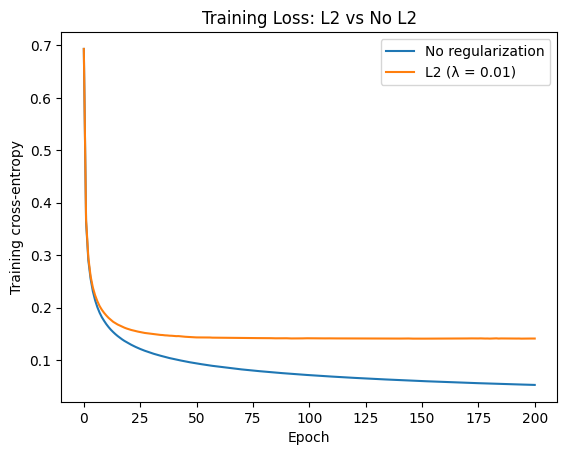

In [ ]:
plt.plot(optimizer_no_l2.loss_history, label="No regularization")
plt.plot(optimizer_l2.loss_history, label="L2 (λ = 0.01)")

plt.xlabel("Epoch")
plt.ylabel("Training cross-entropy")
plt.title("Training Loss: L2 vs No L2")
plt.legend()
plt.show()

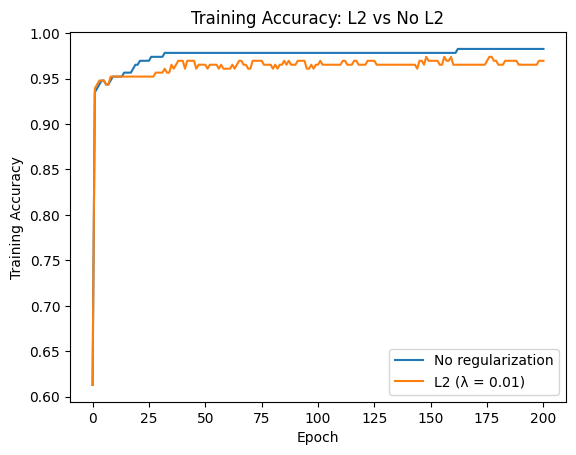

In [ ]:
plt.plot(optimizer_no_l2.accuracy_history, label="No regularization")
plt.plot(optimizer_l2.accuracy_history, label="L2 (λ = 0.01)")

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("Training Accuracy: L2 vs No L2")
plt.legend()
plt.show()

### Effect of Batch Size

Compare convergence and training stability across batch sizes, measuring progress by both epochs and weight updates.

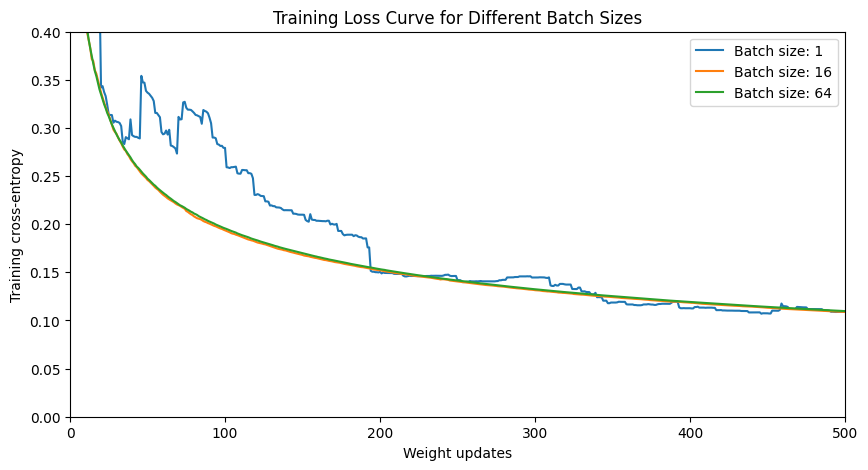

In [ ]:
batch_sizes = [1, 16, 64]

plt.figure(figsize=(10, 5))

for batch_size in batch_sizes:
    optimizer = MiniBatchGradientDescent(batch_size = batch_size, record_by = "update")
    model = LogisticRegression()
    model.fit(X_train, Y_train, optimizer)

    plt.plot(
        optimizer.loss_history,
        label=f"Batch size: {batch_size}"
    )

plt.xlabel("Weight updates")
plt.ylabel("Training cross-entropy")
plt.title("Training Loss Curve for Different Batch Sizes")
plt.xlim(0, 500)
plt.ylim(0, 0.4)
plt.legend()
plt.show()

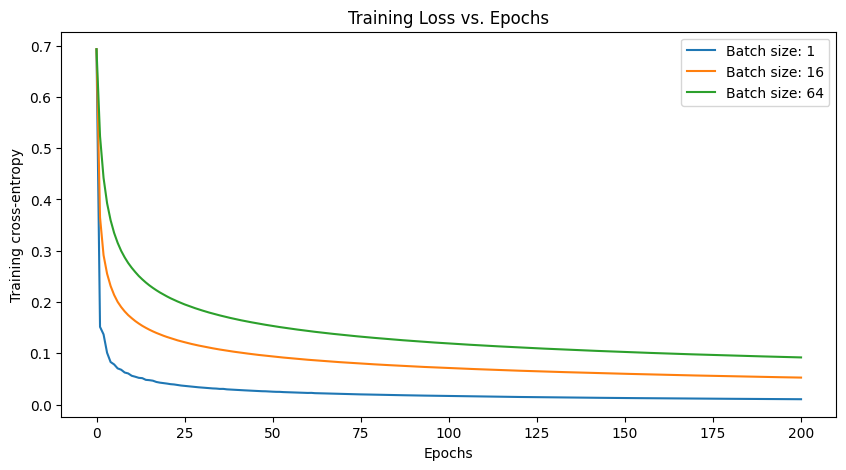

In [ ]:
batch_sizes = [1, 16, 64]

plt.figure(figsize=(10, 5))

for batch_size in batch_sizes:
    optimizer = MiniBatchGradientDescent(batch_size = batch_size, record_by = "epoch")
    model = LogisticRegression()
    model.fit(X_train, Y_train, optimizer)

    plt.plot(
        optimizer.loss_history,
        label=f"Batch size: {batch_size}"
    )

plt.xlabel("Epochs")
plt.ylabel("Training cross-entropy")
plt.title("Training Loss vs. Epochs")
plt.legend()
plt.show()

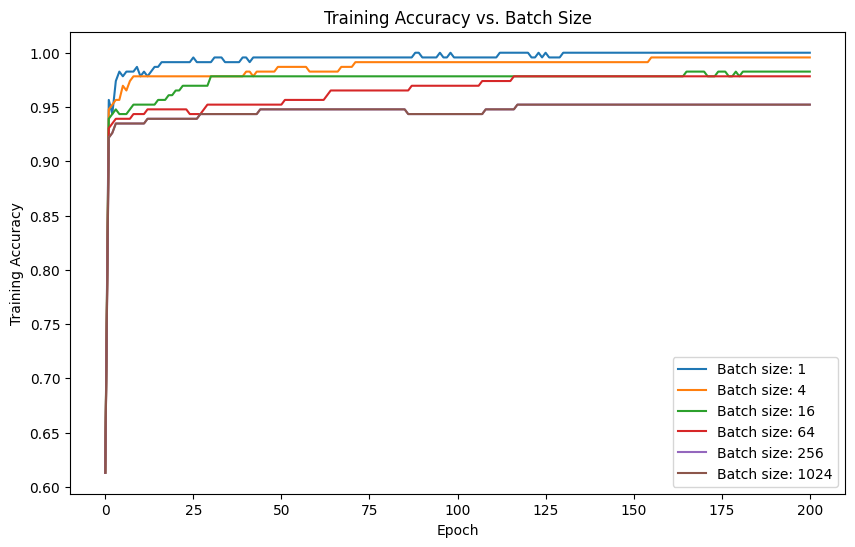

In [ ]:
batch_sizes = [1, 4, 16, 64, 256, 1024]

plt.figure(figsize=(10, 6))

for batch_size in batch_sizes:
    optimizer = MiniBatchGradientDescent(batch_size)
    model = LogisticRegression()
    model.fit(X_train, Y_train, optimizer)

    plt.plot(
        optimizer.accuracy_history,
        label=f"Batch size: {batch_size}"
    )

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("Training Accuracy vs. Batch Size")
plt.legend()
plt.show()

# Part 2: Hyperparameter Tuning

Evaluate model configurations using 10-fold cross-validation, comparing mean accuracy and cross-entropy loss across folds.

In [ ]:
class CrossValidation:

  def __init__(self, k_fold = 10, b_sizes = [1, 16, 64], learning_rate_sizes = [1, .1, .01, .001, .0001],
               epochs_size = [50, 100, 200], l2_reg = [0, 0.01, 0.05, 0.1], w_gen = None, train_info = False):
    self.k_fold = k_fold
    self.b_sizes = b_sizes
    self.learning_rate_sizes = learning_rate_sizes
    self.epochs_size = epochs_size
    self.l2_reg = l2_reg
    self.w_gen = w_gen

    # Variables that temporily store information during training
    self.train_info = train_info
    self.training_ce = None
    self.training_acc = None
    self.temp_ce = None
    self.temp_acc = None
    self.all_train_ce = []
    self.all_train_acc = []

  def get_folds(self, x, y, n):
    """
    Gets nth fold. Returns new x,y and new valdation set
    """
    length = len(y)
    lower_bound = (n - 1) * length // self.k_fold
    upper_bound = n * length // self.k_fold

    x_val = x[lower_bound:upper_bound]
    y_val = y[lower_bound:upper_bound]

    x = np.concatenate(
        (x[:lower_bound], x[upper_bound:]), axis=0
    )
    y_new = np.concatenate(
        (y[:lower_bound], y[upper_bound:]), axis=0
    )
    mean = x[:, :-1].mean(axis=0)
    std = x[:, :-1].std(axis=0)
    std[std == 0] = 1

    x_new = x.copy()
    x_val = x_val.copy()

    x_new[:, :-1] = (x[:, :-1] - mean) / std
    x_val[:, :-1] = (x_val[:, :-1] - mean) / std
    return x_new, y_new, x_val, y_val

  def run_once(self, model, optimizer, x, y, x_val, y_val):
    """
    Returns cross entropy and accuracy value
    """

    model.fit(x, y, optimizer)

    if self.train_info == True:
      self.temp_ce = model.loss(x, y, model.w)
      self.temp_acc = model.accuracy(x, y, model.w)

    return  model.loss(x_val, y_val, model.w), model.accuracy(x_val, y_val, model.w)

  def run_k(self, b, lr, e, reg, wg = None):
    """
    Run K sessions given hyperparameters, returns mean cross-entropy, accuracy
    and std deviation across folds.
    """
    if self.train_info == True:
      self.training_ce = np.empty(self.k_fold)
      self.training_acc = np.empty(self.k_fold)


    cross_entropies = np.empty( (self.k_fold,1) )
    accuracies = np.empty( (self.k_fold,1) )

    for i in range(1, self.k_fold+1):
      optimizer = MiniBatchGradientDescent(b, lr, e)
      model = LogisticRegression(reg, wg=wg)

      x, y, x_val, y_val = self.get_folds(X_train_unorm, Y_train, i)

      cross_entr, accu = self.run_once(model, optimizer, x, y, x_val, y_val)

      cross_entropies[i-1] = cross_entr
      accuracies[i-1] = accu

      if self.train_info == True:
        self.training_ce[i-1] = self.temp_ce
        self.training_acc[i-1] = self.temp_acc

    if self.train_info == True:
      self.all_train_ce.append( np.mean(self.training_ce) )
      self.all_train_acc.append( np.mean(self.training_acc) )

    return np.mean(cross_entropies), np.std(cross_entropies), np.mean(accuracies), np.std(accuracies)


  def run_w_gen(self):
    results = []
    self.all_train_ce = []
    self.all_train_acc = []

    for b in self.b_sizes:
      for lr in self.learning_rate_sizes:
        for e in self.epochs_size:
          for reg in self.l2_reg:
            for wg in self.w_gen:
              cr_entr_mean, cr_entr_std, acc_mean, acc_std = self.run_k(b, lr, e, reg, wg)
              results.append({
                          "batch_size": b,
                          "learning_rate": lr,
                          "epochs": e,
                          "l2_reg": reg,
                          "w_gen": wg,
                          "ce_mean": cr_entr_mean,
                          "ce_std": cr_entr_std,
                          "accuracy_mean": acc_mean,
                          "accuracy_std": acc_std
                      })

    return results
  def run(self):
    results = []
    self.all_train_ce = []
    self.all_train_acc = []

    if self.w_gen is not None:
      return self.run_w_gen()

    for b in self.b_sizes:
      for lr in self.learning_rate_sizes:
        for e in self.epochs_size:
          for reg in self.l2_reg:

            cr_entr_mean, cr_entr_std, acc_mean, acc_std = self.run_k(b, lr, e, reg)
            results.append({
                        "batch_size": b,
                        "learning_rate": lr,
                        "epochs": e,
                        "l2_reg": reg,
                        "ce_mean": cr_entr_mean,
                        "ce_std": cr_entr_std,
                        "accuracy_mean": acc_mean,
                        "accuracy_std": acc_std
                    })

    return results

In [ ]:
CV = CrossValidation(l2_reg=[0.01], w_gen=[None, "Ones", "Uniform", "Normal"])
results = pd.DataFrame(CV.run())


### Highest-Performing Configurations

In [ ]:
display(results.sort_values(by="ce_mean").head(10))
display(results.sort_values(by="accuracy_mean", ascending=False).head(10))

,batch_size,learning_rate,epochs,l2_reg,w_gen,ce_mean,ce_std,accuracy_mean,accuracy_std
123,64,1.00,50,0.01,Normal,0.307472,0.240866,0.908696,0.065795
70,16,1.00,200,0.01,Uniform,0.308556,0.258493,0.930435,0.052174
124,64,1.00,100,0.01,None,0.309048,0.244805,0.913043,0.054996
122,64,1.00,50,0.01,Uniform,0.309959,0.265504,0.917391,0.049382
79,16,0.10,100,0.01,Normal,0.311683,0.249574,0.913043,0.061488
127,64,1.00,100,0.01,Normal,0.312003,0.258845,0.917391,0.056522
71,16,1.00,200,0.01,Normal,0.312249,0.253769,0.921739,0.054304
65,16,1.00,100,0.01,Ones,0.312252,0.252028,0.921739,0.057680
35,1,0.01,200,0.01,Normal,0.312424,0.251695,0.917391,0.056522
31,1,0.01,100,0.01,Normal,0.312576,0.251006,0.917391,0.056522


,batch_size,learning_rate,epochs,l2_reg,w_gen,ce_mean,ce_std,accuracy_mean,accuracy_std
70,16,1.00,200,0.01,Uniform,0.308556,0.258493,0.930435,0.052174
20,1,0.10,200,0.01,None,0.318646,0.252370,0.926087,0.047826
69,16,1.00,200,0.01,Ones,0.313881,0.256741,0.926087,0.051628
120,64,1.00,50,0.01,None,0.317686,0.251491,0.921739,0.057680
65,16,1.00,100,0.01,Ones,0.312252,0.252028,0.921739,0.057680
21,1,0.10,200,0.01,Ones,0.330005,0.289535,0.921739,0.046828
71,16,1.00,200,0.01,Normal,0.312249,0.253769,0.921739,0.054304
125,64,1.00,100,0.01,Ones,0.313640,0.256751,0.921739,0.050704
28,1,0.01,100,0.01,None,0.313234,0.253244,0.917391,0.056522
29,1,0.01,100,0.01,Ones,0.315232,0.255657,0.917391,0.056522


### Lowest-Performing Configurations

In [ ]:
display(results.sort_values(by="ce_mean", ascending=False).head(10))
display(results.sort_values(by="accuracy_mean").head(10))

,batch_size,learning_rate,epochs,l2_reg,w_gen,ce_mean,ce_std,accuracy_mean,accuracy_std
169,64,0.0001,50,0.01,Ones,4.555648,2.000380,0.613043,0.071310
173,64,0.0001,100,0.01,Ones,4.537911,1.994477,0.613043,0.071310
109,16,0.0001,50,0.01,Ones,4.515730,1.987380,0.613043,0.071310
177,64,0.0001,200,0.01,Ones,4.502167,1.982712,0.613043,0.071310
113,16,0.0001,100,0.01,Ones,4.458440,1.968616,0.617391,0.063900
157,64,0.0010,50,0.01,Ones,4.397427,1.948447,0.617391,0.063900
117,16,0.0001,200,0.01,Ones,4.345205,1.931392,0.617391,0.063900
171,64,0.0001,50,0.01,Normal,4.225035,5.591509,0.534783,0.123052
161,64,0.0010,100,0.01,Ones,4.223555,1.887933,0.621739,0.070241
103,16,0.0010,100,0.01,Normal,4.029574,2.915288,0.565217,0.075307


,batch_size,learning_rate,epochs,l2_reg,w_gen,ce_mean,ce_std,accuracy_mean,accuracy_std
170,64,0.0001,50,0.01,Uniform,2.567098,1.088549,0.473913,0.140819
114,16,0.0001,100,0.01,Uniform,1.833953,0.742137,0.473913,0.123665
167,64,0.0010,200,0.01,Normal,3.358424,1.631044,0.478261,0.101034
175,64,0.0001,100,0.01,Normal,3.294213,1.269880,0.491304,0.148145
166,64,0.0010,200,0.01,Uniform,2.015629,1.164183,0.504348,0.127799
119,16,0.0001,200,0.01,Normal,2.891874,1.305734,0.508696,0.119940
110,16,0.0001,50,0.01,Uniform,1.908856,0.867804,0.513043,0.152856
159,64,0.0010,50,0.01,Normal,3.072542,1.006660,0.517391,0.163203
174,64,0.0001,100,0.01,Uniform,2.145128,0.992980,0.517391,0.092129
111,16,0.0001,50,0.01,Normal,2.869129,1.119370,0.521739,0.179265


# Part 3: L2 Regularization Analysis

Examine the relationship between regularization strength, training performance, and validation performance.

In [ ]:
CV_bias = CrossValidation(b_sizes=[16], learning_rate_sizes = [.1], epochs_size = [200], l2_reg = [0, .000001, .00001, .0001, .001, .01, 0.1, 1], train_info=True)
results_bias = pd.DataFrame(CV_bias.run())

In [ ]:
display(results_bias)

,batch_size,learning_rate,epochs,l2_reg,ce_mean,ce_std,accuracy_mean,accuracy_std
0,16,0.1,200,0.000000,0.407450,0.463136,0.921739,0.060870
1,16,0.1,200,0.000001,0.406716,0.462502,0.921739,0.060870
2,16,0.1,200,0.000010,0.406705,0.462026,0.921739,0.060870
3,16,0.1,200,0.000100,0.401453,0.454740,0.921739,0.060870
4,16,0.1,200,0.001000,0.364107,0.398176,0.921739,0.060870
5,16,0.1,200,0.010000,0.312924,0.252374,0.917391,0.056522
6,16,0.1,200,0.100000,0.355220,0.113684,0.895652,0.055679
7,16,0.1,200,1.000000,0.509968,0.037480,0.778261,0.081224


In [ ]:
l2_regs = results_bias['l2_reg']
ce_means = results_bias['ce_mean']
acc_means = results_bias['accuracy_mean']
train_acc_means = CV_bias.all_train_acc
train_ce_means = CV_bias.all_train_ce



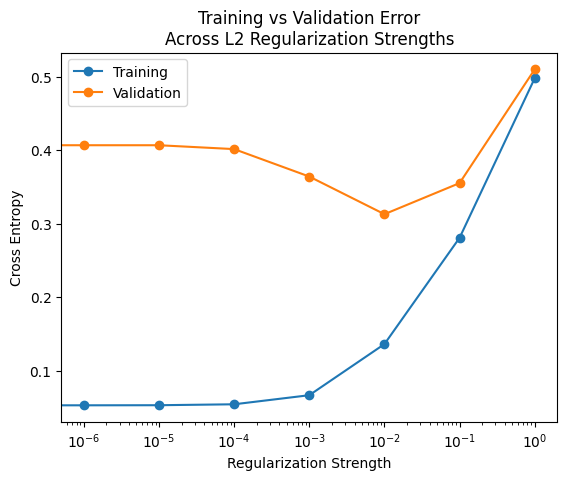

In [ ]:
plt.plot(l2_regs, train_ce_means, "o-", label="Training")
plt.plot(l2_regs, ce_means, "o-", label="Validation")
plt.xscale('log')

plt.title("Training vs Validation Error\nAcross L2 Regularization Strengths")
plt.xlabel("Regularization Strength")
plt.ylabel("Cross Entropy")
plt.legend()
plt.show()

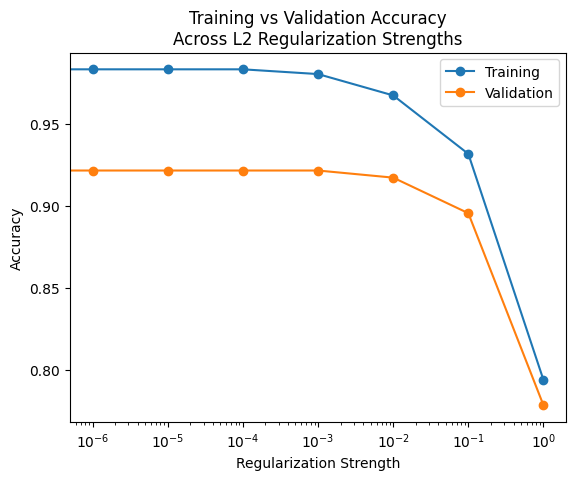

In [ ]:
plt.plot(l2_regs, train_acc_means, "o-", label="Training")
plt.plot(l2_regs, acc_means, "o-", label="Validation")
plt.xscale('log')

plt.title("Training vs Validation Accuracy\nAcross L2 Regularization Strengths")
plt.xlabel("Regularization Strength")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

**Selected regularization strength:** λ = 0.1

### Final Model Evaluation

In [ ]:
optimizer_final = MiniBatchGradientDescent()
model_final = LogisticRegression(l2_reg = 0.1)
model_final.fit(X_train, Y_train, optimizer_final)

print(model_final.loss(X_test, Y_test, model_final.w))
print(model_final.accuracy(X_test, Y_test, model_final.w))

0.33981810568911774
0.8970487302676733


### Evaluation with Tuned Hyperparameters

Repeat the regularization analysis using the hyperparameters selected through cross-validation, then evaluate the chosen model on the held-out test set.

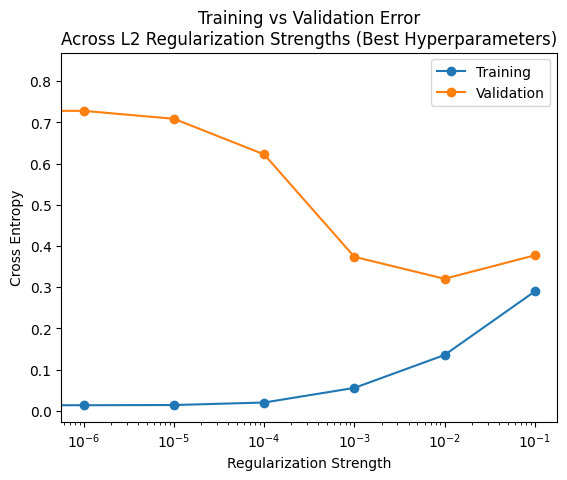

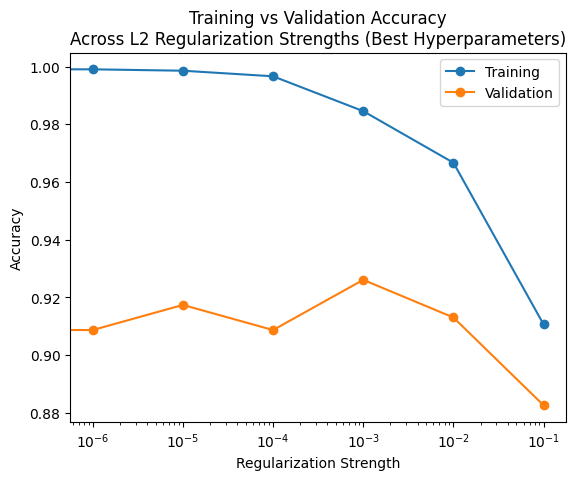

In [ ]:
CV_bias_best = CrossValidation(b_sizes=[16], learning_rate_sizes = [1.0], epochs_size = [200], l2_reg = [0, .000001, .00001, .0001, .001, .01, 0.1], w_gen=["Normal"], train_info=True)
results_bias_best = pd.DataFrame(CV_bias_best.run())

l2_regs = results_bias_best['l2_reg']
ce_means = results_bias_best['ce_mean']
acc_means = results_bias_best['accuracy_mean']
train_acc_means = CV_bias_best.all_train_acc
train_ce_means = CV_bias_best.all_train_ce

plt.plot(l2_regs, train_ce_means, "o-", label="Training")
plt.plot(l2_regs, ce_means, "o-", label="Validation")
plt.xscale('log')

plt.title("Training vs Validation Error\nAcross L2 Regularization Strengths (Best Hyperparameters)")
plt.xlabel("Regularization Strength")
plt.ylabel("Cross Entropy")
plt.legend()
plt.show()

plt.plot(l2_regs, train_acc_means, "o-", label="Training")
plt.plot(l2_regs, acc_means, "o-", label="Validation")
plt.xscale('log')

plt.title("Training vs Validation Accuracy\nAcross L2 Regularization Strengths (Best Hyperparameters)")
plt.xlabel("Regularization Strength")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [ ]:
optimizer_final_best = MiniBatchGradientDescent(16, 1.0, 200)
model_final_best = LogisticRegression(l2_reg = 0.01, wg="Normal")
model_final_best.fit(X_train, Y_train, optimizer_final_best)

print(model_final_best.loss(X_test, Y_test, model_final_best.w))
print(model_final_best.accuracy(X_test, Y_test, model_final_best.w))

0.34959720223587276
0.8897277510867079


# Part 4: L1 Regularization with Scikit-learn

Use scikit-learn's logistic regression implementation to study coefficient paths, feature sparsity, and cross-validation accuracy as regularization strength varies.

In [ ]:
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

# Setup grid of C values
Cs = np.logspace(-4, 4, 30)
coef_paths = []
non_zero_counts = []

# Exclude the added 'bias' column
X_train_l1 = X_train[:, :-1]
Y_train_arr = Y_train.ravel()

# Fit across the path using warm_start=True for speed
classifier = SklearnLogisticRegression(
    penalty="l1",
    solver="saga",
    warm_start=True,
    max_iter=3000,
    random_state=2026,
)

for c in Cs:
    classifier.set_params(C=c)
    classifier.fit(X_train_l1, Y_train_arr)

    # Store coefficient vector
    coefs = classifier.coef_[0].copy()
    coef_paths.append(coefs)

    # Number of non-zero coefficients
    non_zero_counts.append(np.sum(np.abs(coefs) > 0))

coef_paths = np.array(coef_paths)
print("Coefficient path shape:", coef_paths.shape)

Coefficient path shape: (30, 57)


The manually added bias column is removed because scikit-learn fits an intercept by default.

## Coefficient Paths and Feature Sparsity

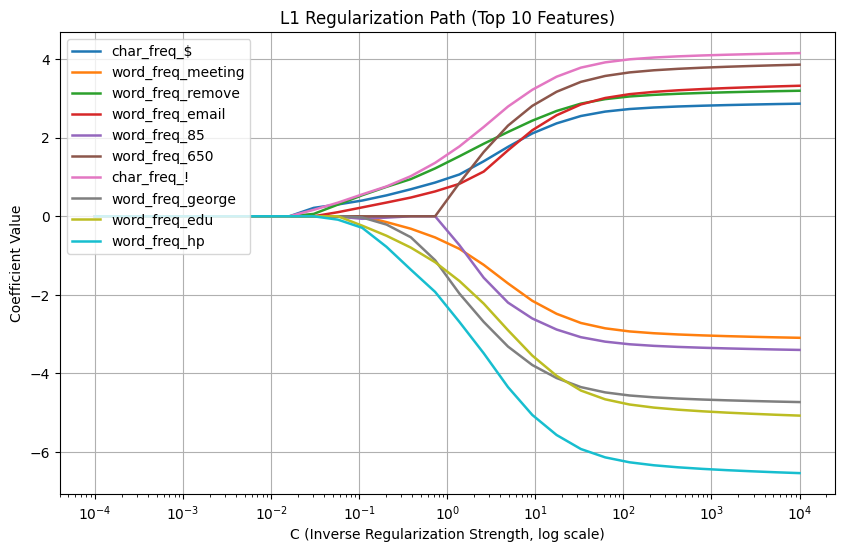

In [ ]:
plt.figure(figsize=(10, 6))

final_abs_weights = np.abs(coef_paths[-1])
# Selects features by final coefficient magnitudes, rather than by the order in which they become nonzero.
top_indices = np.argsort(final_abs_weights)[-10:]
feature_names = spambase.data.features.columns

for i in top_indices:
    plt.plot(Cs, coef_paths[:, i], label=feature_names[i], linewidth=1.8)

plt.xscale("log")
plt.xlabel("C (Inverse Regularization Strength, log scale)")
plt.ylabel("Coefficient Value")
plt.title("L1 Regularization Path (Top 10 Features)")
plt.grid(True)
plt.legend(loc="upper left")
plt.show()

Positive coefficients indicate an association with spam, while negative coefficients indicate an association with legitimate email. The coefficient values indicate the significance of that association.

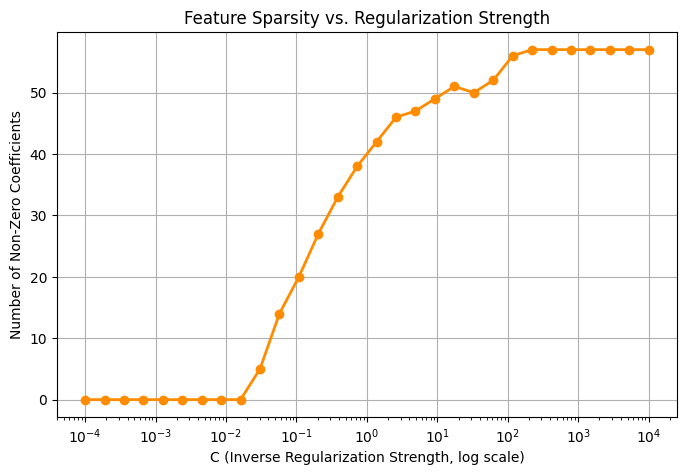

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(Cs, non_zero_counts, marker="o", color="darkorange", linewidth=2)
plt.xscale("log")
plt.xlabel("C (Inverse Regularization Strength, log scale)")
plt.ylabel("Number of Non-Zero Coefficients")
plt.title("Feature Sparsity vs. Regularization Strength")
plt.grid(True)
plt.show()

## Cross-Validation Performance

In [ ]:
# CV Performance vs C using K-Fold split
K = 10
cv_task4 = CrossValidation(k_fold=K)
cv_accuracies = np.zeros((len(Cs), K))
Y_train_flat = Y_train.ravel()

for fold in range(1, K + 1):
    # Split and normalize in-fold helper
    x_tr, y_tr, x_val, y_val = cv_task4.get_folds(
        X_train_unorm, Y_train_flat, fold
    )

    # Drop the manual bias column
    x_tr = x_tr[:, :-1]
    x_val = x_val[:, :-1]

    # Initialize L1 logistic regression
    clf = SklearnLogisticRegression(
        penalty="l1",
        solver="saga",
        warm_start=True,
        max_iter=10000,
        random_state=2026,
    )

    # Sweep across C for this fold
    for c_i, c in enumerate(Cs):
        clf.set_params(C=float(c))
        clf.fit(x_tr, y_tr)
        cv_accuracies[c_i, fold - 1] = np.mean(clf.predict(x_val) == y_val)

# Aggregate results across folds
mean_cv_acc = cv_accuracies.mean(axis=1)
best_c_i = np.argmax(mean_cv_acc)
best_C = Cs[best_c_i]

print("Optimal C: ", round(best_C, 4))
print("Best Mean CV Accuracy: ", round(mean_cv_acc[best_c_i], 4))

Optimal C:  2.5929
Best Mean CV Accuracy:  0.9348


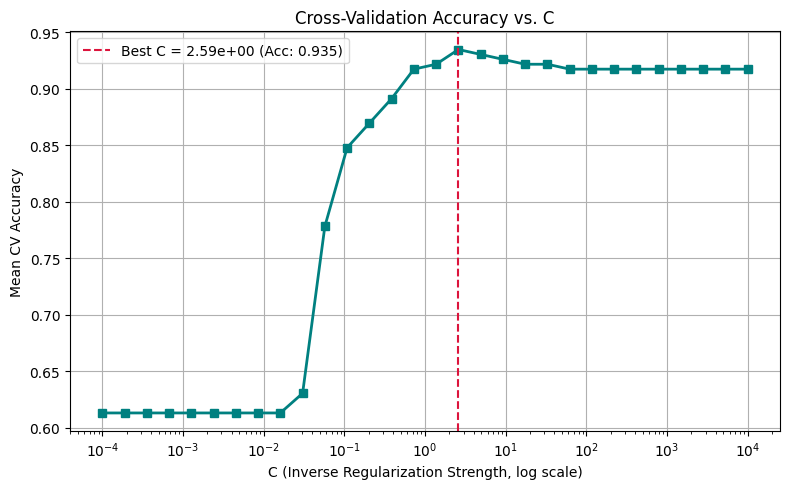

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(Cs, mean_cv_acc, marker="s", color="teal", linewidth=2)
plt.axvline(
    best_C,
    color="crimson",
    linestyle="--",
    label=f"Best C = {best_C:.2e} (Acc: {mean_cv_acc[best_c_i]:.3f})",
)
plt.xscale("log")
plt.xlabel("C (Inverse Regularization Strength, log scale)")
plt.ylabel("Mean CV Accuracy")
plt.title("Cross-Validation Accuracy vs. C")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

**Best regularization parameter:** C ≈ 2.59, achieving approximately 93.48% mean 10-fold cross-validation accuracy.

---

For a detailed discussion of the methodology, results, and limitations, see the [Project Report](https://github.com/BogdanRudnitski/logistic-regression-spam-classification/blob/main/report.pdf).